# ChatGPT, Claude and Muse paid plans: e-receipt and card coverage, overlap and movement

**Question (2026-10-13).** Do our e-receipt (NIQ) and card (Yodlee) panels capture ChatGPT and Claude consumer paid plans (adds, renewals, cancellations)? If so, can we measure paid-user overlap between ChatGPT, Claude and Muse over time, and movement between them (add-ons and switches) since Muse launched on 2026-09-08?

**Scope (agreed in planning).**

| Decision | Choice |
|---|---|
| Apps / plans | ChatGPT Go, Plus, Pro; Claude Pro, Max; Muse Power, Max. Consumer plans only: ChatGPT Business, Claude Team, API usage and credits are excluded |
| Channels | Direct web, Apple App Store, Google Play, each tagged |
| Window | Data from 2026-01-01 (lookback), reporting from 2026-02-10 for ChatGPT / Claude and from launch for Muse |
| Panels | Never linked (no shared key). NIQ people = `USERID`; Yodlee people = member within a feed (card + bank). Muse is never merged across panels: in-app Muse on NIQ, web Muse on cards |
| Rules | The Muse app's rules (`meta/app/sections.py`, `SUB_GAP_DAYS` / `TENURE_DAYS` / `ACTIVE_DAYS`), extended to ChatGPT and Claude (section 3) |
| Output | Notebook only; no tables. Queries reuse `sections.py` helpers so a section can be lifted into the app later |

**Contents.** 1 Coverage · 2 ChatGPT direct-web diagnostic (NIQ) · 3 Subscriber flows · 4 Paid-user overlap · 5 Movement between apps · 6 Caveats

## Findings (run of 2026-10-13; cards complete through 10-08, e-receipts through 10-11)

**1. Do the panels see ChatGPT and Claude paid plans? Yes, with one big gap.**

| | NIQ e-receipts | Yodlee cards |
|---|---|---|
| People paying, Sep 2026, by channel | ChatGPT: Apple 46k, Google Play 14k, Direct 10k (sign-ups only). Claude: Direct 41k, Apple 7.6k, Google Play 1.7k | ChatGPT: Direct 371k, Google Play 53k. Claude: Direct 87k, Google Play 2.6k |
| Adds / renewals | Yes; tier from the plan name (Claude direct: from price) | Yes; tier from amount bands |
| Cancellations | **Explicit cancellation emails** for every channel | Inferred: a missed renewal while the member is still in the panel |
| Gap | **ChatGPT direct web: sign-up receipt only, no renewals** (1.5% renewal capture, against 83–95% elsewhere); imputed from section 3 on | **App Store invisible** (`APPLE.COM/BILL`) |

NIQ store payers track SensorTower store revenue (payers-per-revenue index 92–114, April = 100), so the store channels look representative.

**2. Paid-user overlap (share of the second app's payers also paying for the first, latest day).**

| | Claude payers also paying ChatGPT | ChatGPT payers also paying Claude | Muse payers also paying ChatGPT | Muse payers also paying Claude |
|---|---|---|---|---|
| NIQ all channels | 14.2% | 6.6% | 28% (79 of 279) | 25% (69 of 279) |
| NIQ ex-Apple | 7.0% | 4.7% | 20% (19 of 96) | 16% (15 of 96) |
| Cards (web + GP) | 26.1% | 5.5% | 27% (19 of 71) | 35% (25 of 71) |

- Cards show the most ChatGPT/Claude overlap because they see ChatGPT web subscribers properly. NIQ ex-Apple is lowest because NIQ's ChatGPT web view is still partial. **Cards are the better read for ChatGPT/Claude overlap**, and NIQ is a lower bound.
- Over time, the share of card Claude payers also paying ChatGPT fell from 33% (March) to 26% (since July) as Claude's base grew. On NIQ it rose from 10% to 14%, partly because the imputed ChatGPT web base builds up from January.
- **About a quarter to a third of Muse payers already pay for ChatGPT or Claude**, on both panels. Muse is a small base (hundreds), so treat this as indicative.

**3. Movement since Muse launched (gross adds 09-08 onward).**

- **Muse adds (NIQ 276 / cards 71):** 28.6% / 25.4% were already paying ChatGPT and 26.8% / 35.2% Claude. 11.6% / 8.5% ended a ChatGPT plan within 30 days, and 14.5% / 7.0% ended a Claude plan. 49.6% / 46.5% were new to all three apps.
- **Claude adds (NIQ / cards):** 7.7% / 5.1% switched from ChatGPT; 11.5% / 18.6% added Claude on top of ChatGPT. The switch share has fallen since spring (NIQ 25.3% in March to 8.2% in September; cards 15.9% to 5.9%).
- **ChatGPT adds:** 2.6% / 1.2% switched from Claude, and 93.5% / 96.2% were new to these apps.
- Recent adds are right-censored: a cancellation still to come is not visible yet, so switch shares for the latest weeks will rise.

**4. Can we build user-overlap analyses from these panels? Yes, within each panel, never across them.** There is no key linking NIQ and Yodlee. Each panel sees a different part of the market (NIQ: all stores but partial ChatGPT web; cards: web + Google Play but no App Store; Muse in-app only on NIQ and web only on cards). The usable design is the one here: overlap computed within each panel and reported side by side.

In [1]:
import re
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import snowflake.connector

APP = Path.cwd().parent / "app"
sys.path.insert(0, str(APP))
import sections as S

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
conn = snowflake.connector.connect(connection_name="default")


def q(sql: str) -> pd.DataFrame:
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    return df


CACHE = Path(".cache/ai_subs")
CACHE.mkdir(parents=True, exist_ok=True)


def cached(name: str, load) -> pd.DataFrame:
    # Pulls are slow (~7 min per Yodlee source); delete the file to re-pull.
    path = CACHE / f"{name}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    df = load()
    df.to_parquet(path)
    return df


RUN = date(2026, 10, 13)                       # fixed, so the cache and the windows agree
START = "2026-01-01"                           # lookback start
TENURE_START = (date.fromisoformat(START) - timedelta(days=S.TENURE_DAYS)).isoformat()
OV_START = "2026-02-10"                        # first day with a full SUB_GAP_DAYS lookback
LAUNCH = S.LAUNCH
CARD_THROUGH = (RUN - timedelta(days=S.CARD_LAG_DAYS)).isoformat()
NIQ_THROUGH = (RUN - timedelta(days=S.NIQ_LAG_DAYS)).isoformat()
GAP, TENURE, ACTIVE = S.SUB_GAP_DAYS, S.TENURE_DAYS, S.ACTIVE_DAYS
ANNUAL_COVER = 370                             # an annual payment covers a year (plus slack)
SWITCH_DAYS = 30                               # A ends within this many days of a B add = a switch
APPS = ["ChatGPT", "Claude", "Muse"]
PAIRS = [("ChatGPT", "Claude"), ("ChatGPT", "Muse"), ("Claude", "Muse")]
print(f"cards through {CARD_THROUGH}, e-receipts through {NIQ_THROUGH}")

cards through 2026-10-08, e-receipts through 2026-10-11


## 0. Pulls

**NIQ** (`SRS_SLICE.COMMON.ITEMS_LIVE`, active mailboxes, as in the app's `NIQ_SQL`). Filtering on exact merchant names first keeps the scan fast (a 12-month description `ILIKE` over all merchants times out). Direct senders are `Chat GPT` and `Anthropic`; store receipts come from `iTunes` and `Google Play`; each has a `* Cancellation` sender. Apple's paid Muse receipt is a bare `Power Plan` / `Maximum Plan` (no app name), so those exact descriptions are pulled too and kept only from launch week.

**Yodlee** (feeds 3, 4, 6, card and bank, `S.CARD_SOURCES`): one pruned range query per source for OpenAI / Anthropic / web-Muse descriptors, with each payer's first and last day transacting with any merchant (the panel-activity test). Card + bank of one feed share `unique_mem_id`, so a person is feed + member.

In [2]:
NIQ_SQL = f'''
    SELECT orderdate::DATE AS day, COALESCE(userid, mailbox_id) AS user_id, mailbox_id, entry_date::DATE AS entry_date,
           merchant_name AS merchant, item_description AS description, item_price AS price
    FROM srs_slice.common.items_live
    WHERE orderdate BETWEEN '{START}' AND '{NIQ_THROUGH}'
      AND mailbox_status ILIKE 'active'
      AND (merchant_name IN ('Chat GPT', 'Chat GPT Cancellation', 'Anthropic', 'Anthropic Cancellation')
           OR (merchant_name IN ('iTunes', 'Google Play', 'iTunes Cancellation', 'Google Play Cancellation')
               AND (item_description ILIKE '%chatgpt%' OR item_description ILIKE '%claude%'
                    OR item_description ILIKE '%muse from meta%'
                    OR item_description IN ('Power Plan', 'Maximum Plan'))))
'''
niq_raw = cached("niq", lambda: q(NIQ_SQL))
niq_raw["day"] = pd.to_datetime(niq_raw.day)
niq_raw["entry_date"] = pd.to_datetime(niq_raw.entry_date)
print(f"NIQ: {len(niq_raw):,} rows, {niq_raw.user_id.nunique():,} users, {niq_raw.mailbox_id.nunique():,} mailboxes")

NIQ: 1,527,718 rows, 282,047 users, 282,077 mailboxes


In [3]:
def ai_card_sql(d: str) -> str:
    # Broad: subscriptions plus API / credits / Team, classified in pandas. Bare 'claude' is not used:
    # it matches personal names in transfers and merchants (Musee Claude Monet, Claudette's Cafe).
    # Anthropic billed web plans as 'CLAUDE.AI SUBSCRIPTION' until June 2026, then 'ANTHROPIC* CLAUDE SUB'.
    return (f"({d} ILIKE '%chatg%' OR {d} ILIKE '%openai%' OR {d} ILIKE '%anthropic%' "
            f"OR {d} ILIKE '%claude.ai%' OR {d} ILIKE '%claude by anth%' OR {S.muse_web_sql(d, 'amount')})")


def card_sql(src: dict) -> str:
    d, a, m = src["desc"], src["amt"], src["member"]
    return f'''
        WITH ai AS (
            SELECT CAST({m} AS VARCHAR) AS member, CAST({src['txn']} AS VARCHAR) AS txn_id, {src['date']}::DATE AS day,
                   ROUND({a}, 2) AS amount, {d} AS description, transaction_base_type AS base_type
            FROM {src['table']}
            WHERE {S._window(src, START, CARD_THROUGH)} AND {a} BETWEEN 5 AND 300 AND {ai_card_sql(d)}
        ), act AS (
            SELECT CAST({m} AS VARCHAR) AS member, MIN({src['date']})::DATE AS first_seen,
                   MAX({src['date']})::DATE AS last_seen
            FROM {src['table']}
            WHERE {S._window(src, TENURE_START, CARD_THROUGH)}
              AND CAST({m} AS VARCHAR) IN (SELECT member FROM ai)
            GROUP BY 1
        )
        SELECT '{src['name']}' AS source, ai.*, act.first_seen, act.last_seen
        FROM ai LEFT JOIN act ON act.member = ai.member
    '''


def pull_cards() -> pd.DataFrame:
    with ThreadPoolExecutor(6) as pool:
        return pd.concat(pool.map(lambda s: q(card_sql(s)), S.CARD_SOURCES), ignore_index=True)


card_raw = cached("cards", pull_cards)
for c in ("day", "first_seen", "last_seen"):
    card_raw[c] = pd.to_datetime(card_raw[c])
card_raw["amount"] = card_raw.amount.astype(float)
card_raw["feed"] = card_raw.source.str.extract(r"(F\d)")
card_raw["user_id"] = card_raw.feed + ":" + card_raw.member
print(f"Cards: {len(card_raw):,} rows, {card_raw.user_id.nunique():,} members")
card_raw.groupby(["source", "base_type"]).size().unstack(fill_value=0)

Cards: 4,676,721 rows, 900,064 members


base_type,credit,debit
source,,
Yodlee F3 bank,10739,2764703
Yodlee F3 card,3327,327988
Yodlee F4 bank,474,101816
Yodlee F4 card,2752,497634
Yodlee F6 bank,4204,733569
Yodlee F6 card,7769,221746


In [4]:
ST_SQL = f'''
    SELECT DATE_TRUNC('month', date)::DATE AS month,
           CASE unified_product_key {" ".join(f"WHEN '{S.APP_KEYS[a]}' THEN '{a}'" for a in APPS)} END AS app,
           SUM(revenue) AS revenue, SUM(downloads) AS downloads, SUM(dau) / COUNT(DISTINCT date) AS avg_dau
    FROM sensortower.common.core
    WHERE unified_product_key IN ({", ".join(f"'{S.APP_KEYS[a]}'" for a in APPS)})
      AND country_code = 'US' AND date BETWEEN '{START}' AND '{NIQ_THROUGH}'
    GROUP BY 1, 2
'''
st = cached("sensortower", lambda: q(ST_SQL))
st["month"] = pd.to_datetime(st.month)
st[["revenue", "downloads", "avg_dau"]] = st[["revenue", "downloads", "avg_dau"]].astype(float)

### Classification

**NIQ.** App from the sender or the store description; channel from the sender; kind = `cancel` (cancellation sender, 'cancel' or 'will end on'), `trial`, `charge` (priced) or `confirm` (unpriced sign-up confirmation: Apple's `… $19.99 /month` email, Anthropic's `Pro subscription`). Only charges are payments; cancels are the explicit cancellation flow.

| App | Direct | Apple | Google Play |
|---|---|---|---|
| ChatGPT | `ChatGPT Plus/Go/Pro Subscription` ($20/$8/$100+). `Payment` rows (credits) and `Business` are excluded | `ChatGPT : ChatGPT Plus (Monthly)`; `100 Credits` excluded | `ChatGPT Plus (ChatGPT) Auto-renewing subscription` |
| Claude | Generic `Payment`: tier from price, exactly $20 = Pro, $100 / $200 = Max. Other amounts (extra usage, $25 Team seats) excluded | `Claude by Anthropic : Claude Pro - Monthly (Monthly)` | `Claude Pro Subscription (Claude by Anthropic) …` |
| Muse | none (web Muse sends no receipt) | bare `Power Plan` / `Maximum Plan`, from 2026-09-07 | `Power Plan (Muse from Meta) …` |

**Cards.** App from the descriptor: `CHATG` → ChatGPT (`OPENAI *CHATGPT SUBSCR`, `PAYPAL *OPENAI *CHATGPT`, `APLPAY OPENAI *CHATG`, `GOOGLE *CHATGPT`), `CLAUDE.AI SUBSCRIPTION` (until June 2026) / `ANTHROPIC* CLAUDE SU…` (from June) / `GOOGLE *CLAUDE BY ANTH` → Claude, `METAPAY META.COM` at a web price → Muse. `GOOGLE` → Google Play, else Direct (web, including PayPal / Apple Pay wallets). Apple App Store billing is `APPLE.COM/BILL` with no app name, so it is invisible. Excluded: `CHATGPT CREDIT`, `CLAUDE TEAM`, bare `OPENAI` / `ANTHROPIC` (API). Tier from amount bands (amounts include sales tax).

In [5]:
def has(s: pd.Series, pat: str) -> pd.Series:
    return s.str.contains(pat, case=False, regex=True, na=False)


# ---- NIQ ----
n = niq_raw.copy()
d, m = n.description.fillna(""), n.merchant
n["channel"] = np.select([m.str.startswith("iTunes"), m.str.startswith("Google Play")], ["Apple", "Google Play"], "Direct")
store_muse = (d.isin(["Power Plan", "Maximum Plan"]) & (n.day >= "2026-09-07")) | has(d, "muse from meta")
n["app"] = np.select(
    [m.str.startswith("Chat GPT"), m.str.startswith("Anthropic"), store_muse,
     d.str.startswith("ChatGPT") | has(d, r"\(chatgpt|from openai"), has(d, "claude by anthropic|from anthropic")],
    ["ChatGPT", "Claude", "Muse", "ChatGPT", "Claude"], None)
n["kind"] = np.select(
    [m.str.endswith("Cancellation") | has(d, "cancel|will end on"), has(d, "trial"), n.price.fillna(0) > 0],
    ["cancel", "trial", "charge"], "confirm")
claude_direct_pay = (n.app == "Claude") & (n.channel == "Direct") & (d == "Payment")
n["tier"] = np.select(
    [has(d, "business|team|enterprise"), has(d, "credit") | ((n.app == "ChatGPT") & (d == "Payment")),
     claude_direct_pay & n.price.between(19.99, 20.01), claude_direct_pay & (n.price.between(99.99, 100.01) | n.price.between(199.99, 200.01)),
     claude_direct_pay,
     has(d, r"\bmax|maximum"), has(d, r"\bpro\b"), has(d, r"\bplus\b"), has(d, r"\bgo\b"), has(d, r"\bpower\b")],
    ["Business", "Credits", "Pro", "Max", "Usage", "Max", "Pro", "Plus", "Go", "Power"], "Unknown")
n["annual"] = has(d, r"annual|/year|1 year")
n = n[n.app.notna()]
print(pd.crosstab([n.app, n.channel], [n.kind]))
pd.crosstab([n.app, n.tier], n.channel)

kind                 cancel  charge  confirm  trial
app     channel                                    
ChatGPT Apple         54896  447118    38870      5
        Direct        84137  105083       39      0
        Google Play   19835  106308      305      0
Claude  Apple          8189   55566    15464      0
        Direct        27337  466438    81887      0
        Google Play    3475   11634       65      0
Muse    Apple            16     189      234      0
        Google Play       9      99        0      0


channel            Apple  Direct  Google Play
app     tier                                 
ChatGPT Business       0    2674            1
        Credits     3352   36501            0
        Go         77559   24577        19650
        Max            1       0            1
        Plus      455423  117130        92077
        Pro         4552    8141         1016
        Unknown        2     236        13703
Claude  Credits      225       0            0
        Max         5384   87363          973
        Pro        73610  332527        11995
        Unknown        0       0         2206
        Usage          0  155772            0
Muse    Max           16       0            3
        Power        423       0           96
        Unknown        0       0            9

In [6]:
# ---- Cards ----
c = card_raw[card_raw.base_type.str.lower().eq("debit") | card_raw.base_type.isna()].copy()
u = c.description.fillna("").str.upper()
is_muse = (u.str.contains("METAPAY") & u.str.contains("META.COM") & ~u.str.contains(r"METAPAY ?\*", regex=True))
c["app"] = np.select([u.str.contains("CHATG"), u.str.contains("CLAUDE"), is_muse,
                      u.str.contains("OPENAI"), u.str.contains("ANTHROPIC")],
                     ["ChatGPT", "Claude", "Muse", "ChatGPT", "Claude"], None)
c["channel"] = np.where(u.str.contains("GOOGLE"), "Google Play", "Direct")
a = c.amount
bands = {
    "ChatGPT": [("Go", 7.5, 9.6), ("Plus", 19.5, 22.6), ("Pro", 99.9, 112.6), ("Pro", 199.9, 225.1)],
    "Claude": [("Pro", 17.0, 22.6), ("Max", 99.9, 112.6), ("Max", 124.9, 140.7), ("Max", 199.9, 225.1), ("Max", 249.9, 281.3)],
    "Muse": [(p, lo, hi) for p, (lo, hi) in S.WEB_BUCKETS.items()],
}
tier = pd.Series("Other", index=c.index)
for app_, bs in bands.items():
    for t, lo, hi in bs:
        tier[(c.app == app_) & a.between(lo, hi)] = t
excl = np.select([u.str.contains("CREDIT"), u.str.contains("TEAM"),
                  c.app.isin(["ChatGPT", "Claude"]) & ~u.str.contains(r"CHATG|CLAUDE", regex=True)],
                 ["Credits", "Business", "API"], None)
c["tier"] = np.where(pd.notna(excl), excl, tier)
c["kind"], c["annual"] = "charge", False
c["price"] = c.amount
c = c[c.app.notna()]
pd.crosstab([c.app, c.tier], c.channel)

channel            Direct  Google Play
app     tier                          
ChatGPT API        253075          218
        Business        1            0
        Credits     26319          926
        Go         307643        62439
        Other      122912         5689
        Plus      2473186       344461
        Pro         34479         2074
Claude  API        342713          464
        Business     7529            0
        Credits      1951           54
        Max        118218         1185
        Other       34365          321
        Pro        492835        14326
Muse    Max             2            0
        Power          71            0

In [7]:
CONSUMER = {"ChatGPT": ["Go", "Plus", "Pro"], "Claude": ["Pro", "Max"], "Muse": ["Power", "Max"]}


def consumer(df: pd.DataFrame) -> pd.Series:
    return pd.concat([(df.app == a) & df.tier.isin(t) for a, t in CONSUMER.items()], axis=1).any(axis=1)


# Payments: one per person, app and day (stores and Yodlee can repeat a charge across line items / pending+posted).
niq_pay_raw = (n[(n.kind == "charge") & consumer(n)]
               .sort_values("price", ascending=False)
               .drop_duplicates(["user_id", "app", "day"])
               .assign(tenure_start=lambda x: x.groupby("user_id").entry_date.transform("min"),
                       last_seen=pd.NaT, imputed=False))
niq_pay_raw["last_seen"] = pd.to_datetime(niq_pay_raw.last_seen)
niq_cancel = (n[(n.kind == "cancel") & (n.tier.isin(sum(CONSUMER.values(), [])) | (n.tier == "Unknown"))]
              .drop_duplicates(["user_id", "app", "day"]))
card_pay = (c[consumer(c)].sort_values("amount", ascending=False)
            .drop_duplicates(["user_id", "app", "day"])
            .assign(tenure_start=lambda x: x.first_seen, imputed=False))
for name, p in [("NIQ", niq_pay_raw), ("Cards", card_pay)]:
    print(f"{name}: {len(p):,} consumer payments, {p.user_id.nunique():,} people")
print(f"NIQ cancellation notices: {len(niq_cancel):,}")

NIQ: 987,998 consumer payments, 234,900 people


Cards: 3,782,470 consumer payments, 825,113 people
NIQ cancellation notices: 192,480


## 1. Coverage: monthly payers by app, channel and tier

Distinct people with at least one consumer-plan payment in the month. Both panels capture ChatGPT and Claude paid plans in volume. NIQ sees all three channels; cards see direct web and Google Play, but not the App Store.

In [8]:
def monthly(p: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    return (p.assign(month=p.day.dt.to_period("M"))
            .groupby(["month"] + by).user_id.nunique().unstack(by).fillna(0).astype(int))


cov_niq = monthly(niq_pay_raw, ["app", "channel"])
cov_card = monthly(card_pay, ["app", "channel"])
print("NIQ people paying, by app and channel")
display(cov_niq)
print("Card people paying, by app and channel (no Apple)")
display(cov_card)

NIQ people paying, by app and channel


app     ChatGPT                    Claude                     Muse            
channel   Apple Direct Google Play  Apple Direct Google Play Apple Google Play
month                                                                         
2026-01   39723   5480        8388    869   9489         297     0           0
2026-02   38959   5885        9149   1663  13692         435     0           0
2026-03   43690   5655        9722   3957  24031         805     0           0
2026-04   44448   5738       10310   6196  31770        1178     0           0
2026-05   47642   4977       10877   7075  35289        1401     0           0
2026-06   47920   4946       11344   7287  37799        1544     0           0
2026-07   48167   9019       12274   7657  39841        1678     0           0
2026-08   46663  11086       13239   7837  40599        1740     0           0
2026-09   46227  10133       14338   7568  41371        1731    85          53
2026-10   16998   3944        5409   2790  12748         645    98          44

Card people paying, by app and channel (no Apple)


app     ChatGPT             Claude               Muse
channel  Direct Google Play Direct Google Play Direct
month                                                
2026-01  238739       32983  18382         364      0
2026-02  225156       32358  23390         498      0
2026-03  259013       37972  42793        1021      0
2026-04  267470       41243  61589        1525      0
2026-05  269594       42937  71218        1803      0
2026-06  269418       44941  77575        2169      0
2026-07  304900       47602  83479        2199      0
2026-08  345285       49937  85271        2113      0
2026-09  371301       53040  86771        2638     48
2026-10  104371       14142  24114         731     23

Tier mix, Sep 2026 (people):


NIQ   Cards
app     tier                
ChatGPT Go     11691   70180
        Plus   58072  348643
        Pro     1357    6923
Claude  Max    10974   15764
        Pro    40556   74321
Muse    Max        9       1
        Power    132      47

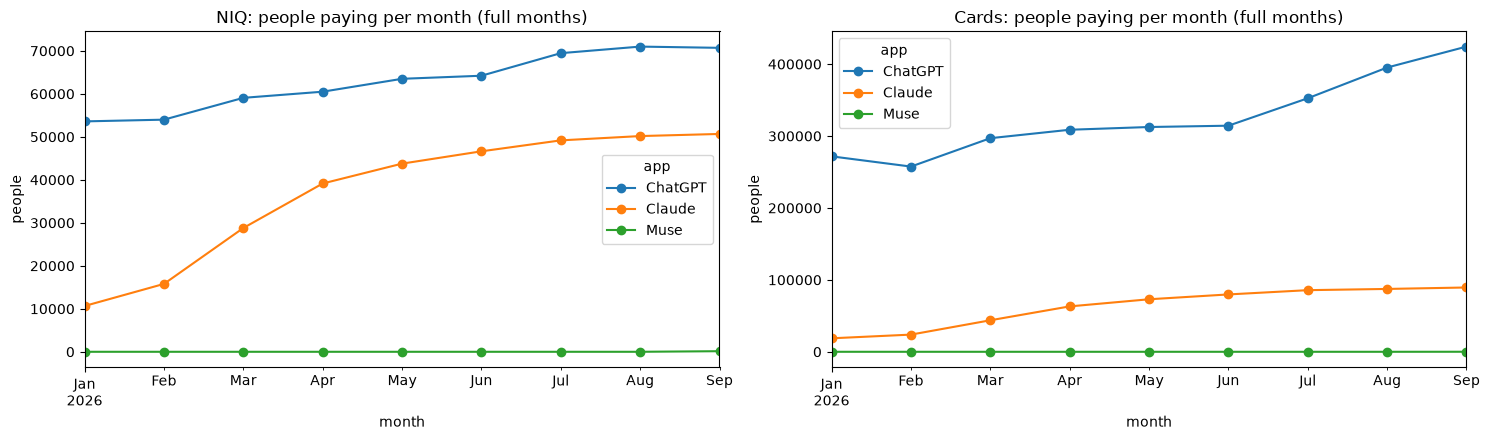

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, cov) in zip(axes, [("NIQ", cov_niq), ("Cards", cov_card)]):
    tot = cov.T.groupby(level="app").sum().T
    tot.index = tot.index.to_timestamp()
    tot.iloc[:-1].plot(ax=ax, marker="o")   # last month is partial
    ax.set_title(f"{name}: people paying per month (full months)")
    ax.set_ylabel("people")
plt.tight_layout()
print("Tier mix, Sep 2026 (people):")
sep = lambda p: p[p.day.dt.to_period("M") == "2026-09"]
display(pd.concat({"NIQ": sep(niq_pay_raw).groupby(["app", "tier"]).user_id.nunique(),
                   "Cards": sep(card_pay).groupby(["app", "tier"]).user_id.nunique()}, axis=1).fillna(0).astype(int))

**Scale check against SensorTower.** NIQ store payers (Apple + Google Play) against SensorTower US in-app revenue, both indexed to April 2026 = 100. The panel is a sample, so the level is arbitrary. What matters is that NIQ store payers track SensorTower store revenue: the payers-per-revenue index stays near 100.

In [10]:
store = niq_pay_raw[niq_pay_raw.channel != "Direct"].assign(month=lambda x: x.day.dt.to_period("M").dt.to_timestamp())
store = store.groupby(["month", "app"]).user_id.nunique().rename("niq_store_payers")
sc = st.set_index(["month", "app"]).join(store, how="left")
sc["payers_per_revenue"] = sc.niq_store_payers / sc.revenue
sc = sc.reset_index()
sc = sc[sc.month < pd.Timestamp(RUN.replace(day=1))]
base = sc[sc.month == "2026-04-01"].set_index("app").payers_per_revenue   # Muse has no April; its index stays empty
sc["payers_per_revenue_idx_apr"] = 100 * sc.payers_per_revenue / sc.app.map(base)
sc["st_revenue_idx_apr"] = 100 * sc.revenue / sc.app.map(sc[sc.month == "2026-04-01"].set_index("app").revenue)
sc.pivot(index="month", columns="app", values=["niq_store_payers", "st_revenue_idx_apr", "payers_per_revenue_idx_apr"]).round(0)

niq_store_payers                st_revenue_idx_apr             payers_per_revenue_idx_apr            
app                 ChatGPT  Claude   Muse            ChatGPT Claude Muse                    ChatGPT Claude Muse
month                                                                                                           
2026-01-01          48101.0  1166.0    NaN               96.0   14.0  NaN                       92.0  114.0  NaN
2026-02-01          48100.0  2098.0    NaN               92.0   25.0  NaN                       96.0  112.0  NaN
2026-03-01          53402.0  4762.0    NaN              102.0   57.0  NaN                       96.0  114.0  NaN
2026-04-01          54750.0  7373.0    NaN              100.0  100.0  NaN                      100.0  100.0  NaN
2026-05-01          58507.0  8475.0    NaN              102.0  110.0  NaN                      105.0  105.0  NaN
2026-06-01          59252.0  8830.0    NaN              106.0  118.0  NaN                      103.0  101.0  NaN
2026-07-01          60429.0  9335.0    NaN              112.0  133.0  NaN                       98.0   95.0  NaN
2026-08-01          59889.0  9577.0    NaN              116.0  135.0  NaN                       94.0   96.0  NaN
2026-09-01          60555.0  9299.0  138.0              117.0  132.0  NaN                       95.0   95.0  NaN

## 2. ChatGPT direct web in NIQ: under-captured?

In NIQ, ChatGPT direct-web payers are a small fraction of its Apple payers, while Claude is the reverse. On cards, ChatGPT direct web dominates. Four checks:

1. **Channel mix against cards.** Cards cannot see Apple, so compare the Direct : Google Play ratio, which both panels can see.
2. **Renewal capture.** For each channel, the share of month-*m* payers who pay again in month *m+1*, among those with no cancellation notice. If OpenAI's direct receipts were captured only at sign-up, this would be near zero.
3. **Cancellations per payer.** Cancellation notices against payers, by channel. A high ratio for Direct means the cancellations get through while the charges do not.
4. **The July 2026 step-up.** Weekly receipts by description, and by mailbox entry cohort (new mailboxes or a sender change).

In [11]:
def ratio(cov):
    out = {}
    for app_ in ("ChatGPT", "Claude"):
        out[app_] = cov[(app_, "Direct")] / cov[(app_, "Google Play")]
    return pd.DataFrame(out)


r = pd.concat({"NIQ Direct/GP": ratio(cov_niq), "Cards Direct/GP": ratio(cov_card)}, axis=1).round(1)
r

NIQ Direct/GP        Cards Direct/GP       
              ChatGPT Claude         ChatGPT Claude
month                                              
2026-01           0.7   31.9             7.2   50.5
2026-02           0.6   31.5             7.0   47.0
2026-03           0.6   29.9             6.8   41.9
2026-04           0.6   27.0             6.5   40.4
2026-05           0.5   25.2             6.3   39.5
2026-06           0.4   24.5             6.0   35.8
2026-07           0.7   23.7             6.4   38.0
2026-08           0.8   23.3             6.9   40.4
2026-09           0.7   23.9             7.0   32.9
2026-10           0.7   19.8             7.4   33.0

In [12]:
def renewal_capture(p: pd.DataFrame, cancels: pd.DataFrame | None) -> pd.DataFrame:
    x = p.assign(month=p.day.dt.to_period("M"))[["user_id", "app", "channel", "month"]].drop_duplicates()
    nxt = x.assign(month=x.month - 1)[["user_id", "app", "month"]].drop_duplicates().assign(paid_next=1)
    x = x.merge(nxt, on=["user_id", "app", "month"], how="left").fillna({"paid_next": 0})
    if cancels is not None:
        cm = cancels.assign(month=cancels.day.dt.to_period("M"))[["user_id", "app", "month"]].drop_duplicates()
        cm = pd.concat([cm, cm.assign(month=cm.month - 1)]).drop_duplicates().assign(cancelled=1)
        x = x.merge(cm, on=["user_id", "app", "month"], how="left")
        x = x[x.cancelled.isna()]
    x = x[(x.month >= "2026-02") & (x.month <= "2026-08")]
    return (x.groupby(["app", "channel"]).paid_next.mean() * 100).round(1)


pd.concat({"NIQ % paying next month": renewal_capture(niq_pay_raw, niq_cancel),
           "Cards % paying next month": renewal_capture(card_pay, None)}, axis=1)

NIQ % paying next month  Cards % paying next month
app     channel                                                        
ChatGPT Apple                           88.7                        NaN
        Direct                           1.5                       85.4
        Google Play                     94.9                       80.7
Claude  Apple                           82.8                        NaN
        Direct                          90.9                       80.1
        Google Play                     93.5                       70.5

In [13]:
cn = niq_cancel.assign(month=niq_cancel.day.dt.to_period("M"))
cn = cn[(cn.month >= "2026-06") & (cn.month <= "2026-09")].groupby(["app", "channel"]).user_id.nunique()
py = niq_pay_raw.assign(month=niq_pay_raw.day.dt.to_period("M"))
py = py[(py.month >= "2026-06") & (py.month <= "2026-09")].groupby(["app", "channel"]).user_id.nunique()
pd.DataFrame({"payers Jun-Sep": py, "cancellers Jun-Sep": cn, "cancellers per 100 payers": (100 * cn / py).round(0)})

payers Jun-Sep  cancellers Jun-Sep  cancellers per 100 payers
app     channel                                                                   
ChatGPT Apple                 65265               18885                       29.0
        Direct                35174               28160                       80.0
        Google Play           17903                5522                       31.0
Claude  Apple                 12125                4471                       37.0
        Direct                53775               13935                       26.0
        Google Play            2443                1182                       48.0
Muse    Apple                    85                   3                        4.0
        Google Play              53                   6                       11.0

In [14]:
g = n[(n.app == "ChatGPT") & (n.channel == "Direct") & (n.day >= "2026-05-01")]
g = g.assign(week=g.day.dt.to_period("W").dt.start_time,
             desc=np.where(g.kind == "cancel", "(cancellation) " + g.tier, g.description.str.slice(0, 32)))
wk = g.groupby(["week", "desc"]).mailbox_id.nunique().unstack().fillna(0).astype(int)
wk = wk[wk.sum().sort_values(ascending=False).index[:7]]
display(wk.iloc[:-1])

coh = niq_pay_raw[(niq_pay_raw.app == "ChatGPT") & (niq_pay_raw.channel == "Direct") & (niq_pay_raw.day >= "2026-05-01")]
coh = coh.assign(month=coh.day.dt.to_period("M"),
                 cohort=np.where(coh.tenure_start >= "2026-06-15", "entered >= 2026-06-15", "entered earlier"))
coh.groupby(["month", "cohort"]).user_id.nunique().unstack().fillna(0).astype(int)

desc,ChatGPT Plus Subscription,(cancellation) Plus,Payment,ChatGPT Go Subscription,(cancellation) Go,(cancellation) Pro,ChatGPT Business Subscription
week,,,,,,,
2026-04-27,398,705,267,98,154,86,6
2026-05-04,1034,1777,535,205,344,230,28
2026-05-11,918,1796,488,238,385,206,63
2026-05-18,879,1546,515,128,325,187,76
2026-05-25,900,1598,493,120,364,191,35
2026-06-01,981,1441,502,131,407,202,37
2026-06-08,1003,1328,481,150,370,194,42
2026-06-15,1009,1333,457,146,394,171,34
2026-06-22,998,1335,376,142,366,163,19


cohort,entered >= 2026-06-15,entered earlier
month,,
2026-05,126,4851
2026-06,131,4815
2026-07,227,8792
2026-08,350,10736
2026-09,290,9843
2026-10,128,3816


**Reading.**

- **The NIQ ChatGPT direct-web receipt is sent at sign-up only.** Only ~1.5% of month-*m* direct payers have a direct receipt in month *m+1*, against 83–95% for every other NIQ channel and 85% for ChatGPT on cards. OpenAI emails a receipt for the first web payment and not for renewals, so NIQ sees ChatGPT web sign-ups, not ChatGPT web subscribers.
- **Cancellations on that channel do get through.** There are 80 cancellers per 100 direct payers, against 26–37 elsewhere: the cancellation email arrives, the renewal receipts do not.
- **Channel mix.** NIQ ChatGPT Direct : Google Play is about 0.7, against about 7 on cards. Claude is in the same range on both panels (NIQ 20–32, cards 33–51), so the gap is specific to OpenAI's renewals.
- **The July 2026 step-up.** Weekly `ChatGPT Plus Subscription` receipts roughly double from the week of 07-06, and Go receipts too. The increase comes from mailboxes that entered the panel before mid-June, not new ones, while weekly cancellation receipts stay flat. Card ChatGPT web payers also grow from June to September (about 269k to 371k people a month), so it is consistent with real sign-up growth rather than a parser or sender change. That is not proven.

**Fix used from section 3 on.** On NIQ, each ChatGPT direct sign-up is carried forward with an imputed monthly renewal (every 30 days) until the person's next ChatGPT direct cancellation notice, their next real direct receipt, or the end of the data. Set `IMPUTE_CHATGPT_DIRECT = False` to see the raw view. Subscribers who signed up before 2026-01-01 and never cancelled stay invisible on NIQ, so NIQ still understates ChatGPT web payers; cards remain the better ChatGPT web view.

In [15]:
IMPUTE_CHATGPT_DIRECT = True
RENEW_EVERY = 30


def impute_chatgpt_direct(pay: pd.DataFrame, cancels: pd.DataFrame, through: str) -> pd.DataFrame:
    d = pay[(pay.app == "ChatGPT") & (pay.channel == "Direct")].sort_values(["user_id", "day"]).copy()
    d["next_real"] = d.groupby("user_id").day.shift(-1)
    cx = cancels[(cancels.app == "ChatGPT") & (cancels.channel == "Direct")][["user_id", "day"]].rename(columns={"day": "cday"})
    m = d[["user_id", "day"]].merge(cx, on="user_id")
    m = m[m.cday >= m.day].groupby(["user_id", "day"]).cday.min()
    d = d.join(m, on=["user_id", "day"])
    stop = pd.concat([d.next_real, d.cday, pd.Series(pd.Timestamp(through) + pd.Timedelta(days=1), index=d.index)], axis=1).min(axis=1)
    k = np.ceil((stop - d.day).dt.days / RENEW_EVERY).astype(int) - 1
    d = d[k > 0].assign(k=k[k > 0])
    syn = d.loc[d.index.repeat(d.k)].copy()
    syn["day"] = syn.day + pd.to_timedelta(syn.groupby(level=0).cumcount().add(1) * RENEW_EVERY, unit="D")
    syn["imputed"] = True
    return pd.concat([pay, syn[pay.columns]], ignore_index=True)


niq_pay = impute_chatgpt_direct(niq_pay_raw, niq_cancel, NIQ_THROUGH) if IMPUTE_CHATGPT_DIRECT else niq_pay_raw
print(f"imputed ChatGPT direct renewals: {niq_pay.imputed.sum():,}")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\2057322752.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  stop = pd.concat([d.next_real, d.cday, pd.Series(pd.Timestamp(through) + pd.Timedelta(days=1), index=d.index)], axis=1).min(axis=1)


imputed ChatGPT direct renewals: 165,900


## 3. Subscriber flows

The Muse app's rules, run per person and app across all of that app's plans and channels:

| Event | Rule |
|---|---|
| Renewal | A payment within `SUB_GAP_DAYS` (35) of the previous payment (370 if the previous one was an annual plan). A tier change on a renewal is a **tier move** (e.g. Plus → Pro), not an add |
| Gross add | A payment that is not a renewal, by a person in the panel for more than `TENURE_DAYS` (35): NIQ = earliest mailbox `ENTRY_DATE`; cards = first day transacting with any merchant |
| New to panel | A non-renewal payment by a person who joined the panel too recently to tell. Its subscription is never counted at either end |
| Cancellation | **NIQ:** an explicit cancellation notice (the plan usually runs to the end of the paid period). **Cards:** no payment within 35 days of the last one, dated at last payment + 35, if the member transacted in the 30 days ending on that date or later. Otherwise it is a **panel exit**, and the gross add that started it becomes an **exited add** |
| Lapse (NIQ) | The card rule's missed renewal, shown as a cross-check on the notices; there are no NIQ panel exits because only active mailboxes are kept |

One deviation from the app: the card activity test uses each member's last transaction day, so a member counts as active at a lapse if they transacted at any point from 30 days before it onwards. The app requires a transaction inside the 30-day window. The result is the same except for a member who went quiet for 30 days and then came back, and this avoids pulling member-day activity for ~250k payers.

In [16]:
def spells(pay: pd.DataFrame, through: str) -> pd.DataFrame:
    p = pay[["user_id", "app", "day", "tier", "channel", "annual", "tenure_start", "last_seen", "imputed"]].sort_values(["user_id", "app", "day"]).copy()
    p["last_seen"] = pd.to_datetime(p.last_seen)
    p["cover"] = np.where(p.annual, ANNUAL_COVER, GAP)
    g = p.groupby(["user_id", "app"], sort=False)
    p["prev_day"], p["prev_cover"], p["prev_tier"] = g.day.shift(), g.cover.shift(), g.tier.shift()
    p["next_day"] = g.day.shift(-1)
    p["is_renewal"] = (p.day - p.prev_day).dt.days <= p.prev_cover
    p["is_tenured"] = (p.day - p.tenure_start).dt.days > TENURE
    p["spell"] = (~p.is_renewal).astype(int).groupby([p.user_id, p.app]).cumsum()
    first = p[~p.is_renewal].set_index(["user_id", "app", "spell"])
    p["unseen_start"] = ~first.is_tenured.reindex(pd.MultiIndex.from_frame(p[["user_id", "app", "spell"]])).values
    p["tier_move"] = p.is_renewal & (p.tier != p.prev_tier)
    p["covered_to"] = p.day + pd.to_timedelta(p.cover - 1, unit="D")
    gap_after = (p.next_day - p.day).dt.days
    p["lapse_day"] = (p.day + pd.to_timedelta(p.cover, unit="D")).where(p.next_day.isna() | (gap_after > p.cover))
    p.loc[p.lapse_day > pd.Timestamp(through), "lapse_day"] = pd.NaT
    p["active_at_lapse"] = p.last_seen >= p.lapse_day - pd.Timedelta(days=ACTIVE - 1)
    return p


def flows(p: pd.DataFrame, panel: str, cancels: pd.DataFrame | None = None) -> pd.DataFrame:
    # one row per event, with exactly one flag set (the reconciliation)
    lapses = p[p.lapse_day.notna()]
    if panel == "Cards":
        exited = lapses.loc[~lapses.active_at_lapse & ~lapses.unseen_start, ["user_id", "app", "spell"]].assign(exit=1)
        pay = p.merge(exited, on=["user_id", "app", "spell"], how="left")
        ext = pay.exit.notna()
    else:
        pay, ext = p.assign(exit=np.nan), pd.Series(False, index=p.index)
    pay_ev = pd.DataFrame({
        "day": pay.day, "app": pay.app,
        "GROSS_ADDS": (~pay.is_renewal & pay.is_tenured & ~ext.values),
        "EXITED_ADDS": (~pay.is_renewal & pay.is_tenured & ext.values),
        "RENEWALS": pay.is_renewal & ~pay.imputed,
        "IMPUTED_RENEWALS": pay.is_renewal & pay.imputed,
        "NEW_TO_PANEL": (~pay.is_renewal & ~pay.is_tenured),
        "TIER_MOVES": pay.tier_move})
    if panel == "Cards":
        lap_ev = pd.DataFrame({
            "day": lapses.lapse_day, "app": lapses.app,
            "CANCELS": ~lapses.unseen_start & lapses.active_at_lapse,
            "PANEL_EXITS": ~lapses.unseen_start & ~lapses.active_at_lapse,
            "UNSEEN_LAPSES": lapses.unseen_start})
        ev = pd.concat([pay_ev, lap_ev])
    else:
        lap_ev = pd.DataFrame({"day": lapses.lapse_day, "app": lapses.app, "LAPSES": ~lapses.unseen_start,
                               "UNSEEN_LAPSES": lapses.unseen_start})
        can_ev = pd.DataFrame({"day": cancels.day, "app": cancels.app, "CANCELS": True})
        ev = pd.concat([pay_ev, lap_ev, can_ev])
    flags = ev.columns.drop(["day", "app"])
    ev[flags] = ev[flags].fillna(False).astype(bool)
    return ev.groupby(["app", "day"]).sum().astype(int)


niq_sp = spells(niq_pay, NIQ_THROUGH)
card_sp = spells(card_pay, CARD_THROUGH)
fl = {"NIQ": flows(niq_sp, "NIQ", niq_cancel), "Cards": flows(card_sp, "Cards")}

# Reconciliation: every payment is exactly one of gross add / exited add / renewal / new to panel.
for name, sp, f in [("NIQ", niq_sp, fl["NIQ"]), ("Cards", card_sp, fl["Cards"])]:
    cats = f[["GROSS_ADDS", "EXITED_ADDS", "RENEWALS", "IMPUTED_RENEWALS", "NEW_TO_PANEL"]].to_numpy().sum()
    assert cats == len(sp), (name, cats, len(sp))
print("reconciled")

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\984396624.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  p["active_at_lapse"] = p.last_seen >= p.lapse_day - pd.Timedelta(days=ACTIVE - 1)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\984396624.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  p["active_at_lapse"] = p.last_seen >= p.lapse_day - pd.Timedelta(days=ACTIVE - 1)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\984396624.py:52: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ev[flags] = ev[flags].fillna(False).astype(bool)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\984396624.py:52: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ev[flags] = ev[flags].fillna(False).astype(bool)


reconciled


In [17]:
def since_launch(f: pd.DataFrame, start=LAUNCH) -> pd.DataFrame:
    f = f.reset_index()
    return f[f.day >= start].groupby("app").sum(numeric_only=True)


print(f"Totals {LAUNCH} to the complete-through date")
display(pd.concat({k: since_launch(v) for k, v in fl.items()}, names=["panel"]))

Totals 2026-09-08 to the complete-through date


GROSS_ADDS  EXITED_ADDS  RENEWALS  IMPUTED_RENEWALS  NEW_TO_PANEL  TIER_MOVES   LAPSES  UNSEEN_LAPSES  CANCELS  PANEL_EXITS
panel app                                                                                                                                 
NIQ   ChatGPT       23392            0     58704             45846           370        1987  13707.0            535    14826          NaN
      Claude         8622            0     48830                 0           104        2879   7706.0            223     6403          NaN
      Muse            276            0         5                 0             3           4      0.0              0       25          NaN
Cards ChatGPT      101884            0    376126                 0          5715        7853      NaN           4153    64023       1843.0
      Claude        20465            0     78529                 0          1017        2645      NaN            655    17014        397.0
      Muse             71            0         0                 0             0           0      NaN              0        0          0.0

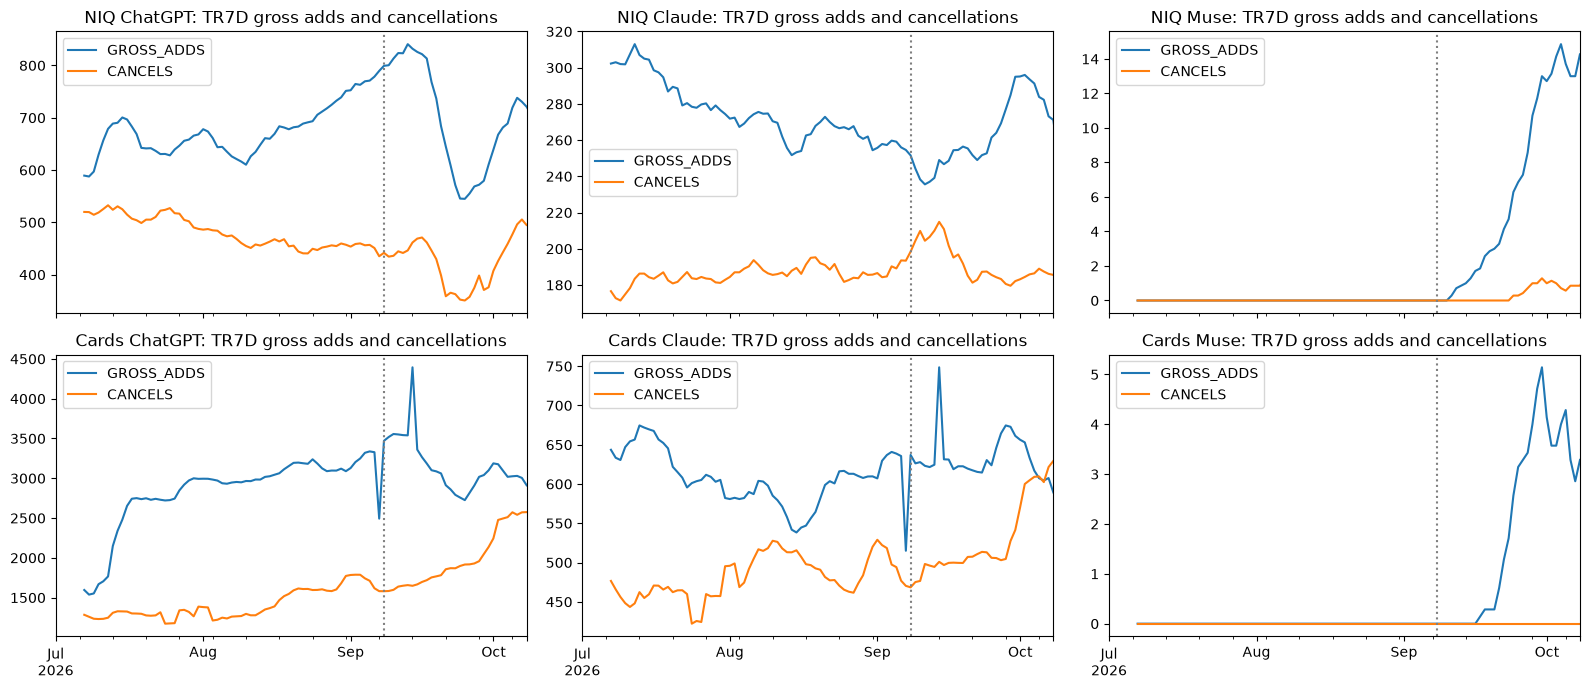

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for row, (panel, f) in enumerate(fl.items()):
    for col, app_ in enumerate(APPS):
        ax = axes[row, col]
        if app_ not in f.index.get_level_values("app"):
            ax.set_title(f"{panel} {app_}: none"); continue
        x = f.loc[app_].reindex(pd.date_range("2026-07-01", NIQ_THROUGH if panel == "NIQ" else CARD_THROUGH), fill_value=0)
        x[["GROSS_ADDS", "CANCELS"]].rolling(7).mean().plot(ax=ax)
        ax.set_title(f"{panel} {app_}: TR7D gross adds and cancellations")
        ax.axvline(pd.Timestamp(LAUNCH), color="grey", ls=":")
plt.tight_layout()

## 4. Paid-user overlap over time

A person is **active** on an app on a day if a payment covers it: within 35 days of a monthly payment (370 for annual). Overlap on a day = people active on both apps. Three views, never merged:

- **NIQ, all channels**: the fullest view of ChatGPT and Claude, and in-app Muse (Apple + Google Play).
- **NIQ, ex-Apple**: Apple payments dropped, like-for-like with cards.
- **Cards**: direct web + Google Play for ChatGPT and Claude; web Muse only.

Daily is fine because the active state only changes when coverage starts or runs out.

In [19]:
def active_matrix(sp: pd.DataFrame, through: str, start=OV_START):
    # spell intervals [first payment, last coverage day] -> people x days boolean, per app
    iv = sp.groupby(["user_id", "app", "spell"]).agg(s=("day", "min"), e=("covered_to", "max")).reset_index()
    days = pd.date_range(start, through)
    iv["s"] = iv.s.clip(lower=days[0]); iv["e"] = iv.e.clip(upper=days[-1])
    iv = iv[iv.s <= iv.e]
    users = pd.Index(iv.user_id.unique())
    out = {}
    for app_, x in iv.groupby("app"):
        diff = np.zeros((len(users), len(days) + 1), dtype=np.int16)
        ui = users.get_indexer(x.user_id)
        np.add.at(diff, (ui, (x.s - days[0]).dt.days.to_numpy()), 1)
        np.add.at(diff, (ui, (x.e - days[0]).dt.days.to_numpy() + 1), -1)
        out[app_] = diff.cumsum(axis=1)[:, :-1] > 0
    return days, out


def overlap(sp: pd.DataFrame, through: str) -> pd.DataFrame:
    days, M = active_matrix(sp, through)
    rows = []
    for a_, b_ in PAIRS:
        if a_ not in M or b_ not in M:
            continue
        na, nb, both = M[a_].sum(0), M[b_].sum(0), (M[a_] & M[b_]).sum(0)
        rows.append(pd.DataFrame({"day": days, "pair": f"{a_} / {b_}", "n_a": na, "n_b": nb, "both": both,
                                  "pct_b_also_a": 100 * both / np.maximum(nb, 1),
                                  "pct_a_also_b": 100 * both / np.maximum(na, 1)}))
    return pd.concat(rows)


views = {
    "NIQ all channels": (niq_sp, NIQ_THROUGH),
    "NIQ ex-Apple": (spells(niq_pay[niq_pay.channel != "Apple"], NIQ_THROUGH), NIQ_THROUGH),
    "Cards (web + GP)": (card_sp, CARD_THROUGH),
}
ov = pd.concat({k: overlap(sp, th) for k, (sp, th) in views.items()}, names=["view"]).reset_index(level=0)
ov.loc[ov.pair.str.contains("Muse") & (ov.day < LAUNCH), ["n_b", "both", "pct_b_also_a", "pct_a_also_b"]] = np.nan
latest = ov[ov.day == ov.groupby("view").day.transform("max")]
latest.set_index(["view", "pair"])[["day", "n_a", "n_b", "both", "pct_b_also_a", "pct_a_also_b"]].round(1)

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\984396624.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  p["active_at_lapse"] = p.last_seen >= p.lapse_day - pd.Timedelta(days=ACTIVE - 1)


day     n_a      n_b     both  pct_b_also_a  pct_a_also_b
view             pair                                                                             
NIQ all channels ChatGPT / Claude 2026-10-11  113461  53149.0   7537.0          14.2           6.6
                 ChatGPT / Muse   2026-10-11  113461    279.0     79.0          28.3           0.1
                 Claude / Muse    2026-10-11   53149    279.0     69.0          24.7           0.1
NIQ ex-Apple     ChatGPT / Claude 2026-10-11   65179  44074.0   3064.0           7.0           4.7
                 ChatGPT / Muse   2026-10-11   65179     96.0     19.0          19.8           0.0
                 Claude / Muse    2026-10-11   44074     96.0     15.0          15.6           0.0
Cards (web + GP) ChatGPT / Claude 2026-10-08  445755  93314.0  24365.0          26.1           5.5
                 ChatGPT / Muse   2026-10-08  445755     71.0     19.0          26.8           0.0
                 Claude / Muse    2026-10-08   93314     71.0     25.0          35.2           0.0

(0.0, 7.380784487334162)

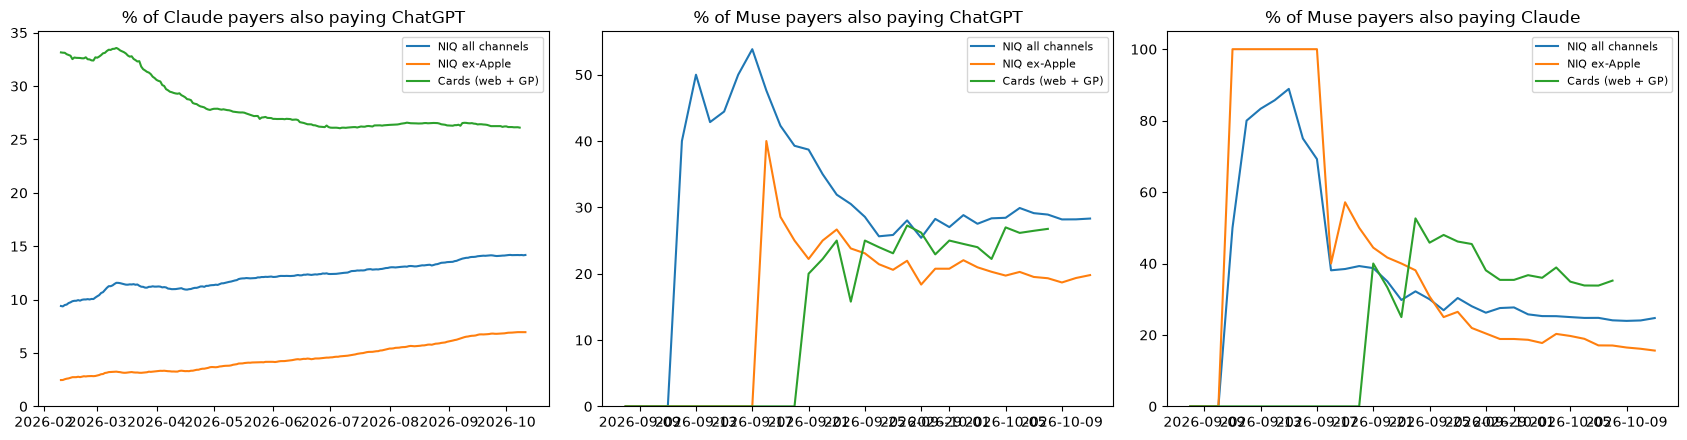

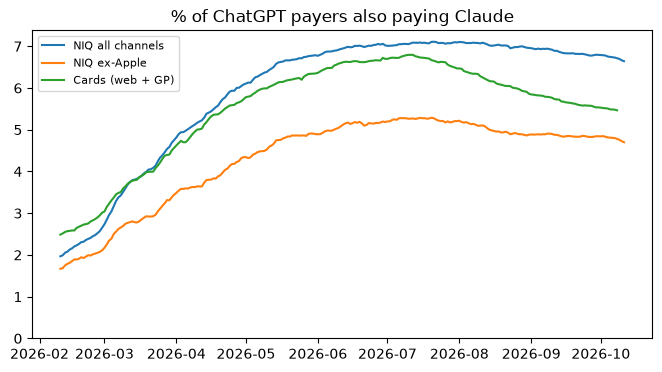

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (pair, x) in zip(axes, ov.groupby("pair", sort=False)):
    a_, b_ = pair.split(" / ")
    for view, y in x.groupby("view", sort=False):
        y = y.dropna(subset=["pct_b_also_a"])
        if "Muse" in pair:
            y = y[y.day >= LAUNCH]
        ax.plot(y.day, y.pct_b_also_a, label=view)
    ax.set_title(f"% of {b_} payers also paying {a_}")
    ax.legend(fontsize=8); ax.set_ylim(bottom=0)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(8, 4))
for view, y in ov[ov.pair == "ChatGPT / Claude"].groupby("view", sort=False):
    ax.plot(y.day, y.pct_a_also_b, label=view)
ax.set_title("% of ChatGPT payers also paying Claude"); ax.legend(fontsize=8); ax.set_ylim(bottom=0)

**Robustness: NIQ by mailbox instead of user.** One NIQ user can link several mailboxes; overlap by mailbox misses a person who pays each app from a different email.

In [21]:
mb_sp = spells(niq_pay.assign(user_id=niq_pay.mailbox_id), NIQ_THROUGH)
mb = overlap(mb_sp, NIQ_THROUGH)
mb = mb[mb.day == mb.day.max()].set_index("pair")[["pct_b_also_a", "pct_a_also_b"]]
us = latest[latest.view == "NIQ all channels"].set_index("pair")[["pct_b_also_a", "pct_a_also_b"]]
pd.concat({"by USERID": us, "by MAILBOX_ID": mb}, axis=1).round(1)

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\984396624.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  p["active_at_lapse"] = p.last_seen >= p.lapse_day - pd.Timedelta(days=ACTIVE - 1)


by USERID              by MAILBOX_ID             
                 pct_b_also_a pct_a_also_b  pct_b_also_a pct_a_also_b
pair                                                                 
ChatGPT / Claude         14.2          6.6          14.2          6.6
ChatGPT / Muse           28.3          0.1          28.3          0.1
Claude / Muse            24.7          0.1          24.7          0.1

## 5. Movement between apps

For each **gross add** on app B (the add rules above: no new-to-panel adds, no exited adds), relative to each other app A held by the same person:

- **Switch A → B**: A ends within ±30 days of the B add. On NIQ, A ends with a cancellation notice or a lapse; on cards, with a cancellation (a lapse while still in the panel).
- **Add-on (A + B)**: the person was active on A the day before the B add, and A did not end within ±30 days.
- **New to these apps**: neither, for every other app.

An add can be a switch from one app and an add-on to another. Adds in the last 30 days are right-censored: an A cancellation still to come is not visible yet. That matters most on cards, where a cancellation is only dated 35 days after the last payment.

In [22]:
def ends(sp: pd.DataFrame, panel: str, cancels: pd.DataFrame | None) -> pd.DataFrame:
    lap = sp[sp.lapse_day.notna()]
    if panel == "Cards":
        lap = lap[lap.active_at_lapse]
    e = lap[["user_id", "app", "lapse_day"]].rename(columns={"lapse_day": "end_day"})
    if cancels is not None:
        e = pd.concat([e, cancels[["user_id", "app", "day"]].rename(columns={"day": "end_day"})])
    return e


def movement(sp: pd.DataFrame, panel: str, cancels: pd.DataFrame | None, start: str) -> pd.DataFrame:
    adds = sp[~sp.is_renewal & sp.is_tenured & (sp.day >= start)][["user_id", "app", "day", "tier", "channel"]]
    if panel == "Cards":   # drop exited adds
        f_exit = sp[sp.lapse_day.notna() & ~sp.active_at_lapse][["user_id", "app", "spell"]]
        sp_first = sp[~sp.is_renewal].merge(f_exit, on=["user_id", "app", "spell"])
        adds = adds.merge(sp_first[["user_id", "app", "day"]].assign(x=1), on=["user_id", "app", "day"], how="left")
        adds = adds[adds.x.isna()].drop(columns="x")
    adds = adds.rename(columns={"app": "to_app", "day": "add_day"})
    iv = sp.groupby(["user_id", "app", "spell"]).agg(s=("day", "min"), e=("covered_to", "max")).reset_index()
    e = ends(sp, panel, cancels)
    rows = []
    for a_ in APPS:
        x = adds[adds.to_app != a_].merge(iv[iv.app == a_], on="user_id")
        active = (x.s < x.add_day) & (x.e >= x.add_day - pd.Timedelta(days=1))
        act = x[active][["user_id", "to_app", "add_day"]].drop_duplicates()
        y = adds[adds.to_app != a_].merge(e[e.app == a_], on="user_id")
        sw = y[(y.end_day - y.add_day).dt.days.abs() <= SWITCH_DAYS][["user_id", "to_app", "add_day"]].drop_duplicates()
        k = ["user_id", "to_app", "add_day"]
        adds = adds.merge(sw.assign(**{f"switch_from_{a_}": True}), on=k, how="left")
        adds = adds.merge(act.assign(**{f"active_{a_}": True}), on=k, how="left")
    flags = [col for col in adds.columns if col.startswith(("switch_from_", "active_"))]
    adds[flags] = adds[flags].fillna(False).astype(bool)
    for a_ in APPS:
        adds[f"addon_to_{a_}"] = adds[f"active_{a_}"] & ~adds[f"switch_from_{a_}"]
    rel = [f"{k}_{a_}" for a_ in APPS for k in ("switch_from", "addon_to")]
    adds["new_to_these_apps"] = ~adds[rel].any(axis=1)
    return adds


mv = {"NIQ all channels": movement(niq_sp, "NIQ", niq_cancel, OV_START),
      "Cards (web + GP)": movement(card_sp, "Cards", None, OV_START)}


def move_table(adds: pd.DataFrame, start=LAUNCH) -> pd.DataFrame:
    a = adds[adds.add_day >= start]
    cols = {}
    for k in ("switch_from", "addon_to"):
        for a_ in APPS:
            cols[f"{k.replace('_', ' ')} {a_}"] = a.groupby("to_app")[f"{k}_{a_}"].sum()
    t = pd.DataFrame(cols)
    t.insert(0, "gross adds", a.groupby("to_app").size())
    t["new to these apps"] = a.groupby("to_app").new_to_these_apps.sum()
    return t.fillna(0).astype(int)


for view, adds in mv.items():
    print(f"{view}: gross adds since {LAUNCH}, by destination app (rows) and relation to each other app (columns)")
    display(move_table(adds))

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\905930596.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  active = (x.s < x.add_day) & (x.e >= x.add_day - pd.Timedelta(days=1))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\905930596.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  active = (x.s < x.add_day) & (x.e >= x.add_day - pd.Timedelta(days=1))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\905930596.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  active = (x.s < x.add_day) & (x.e >= x.add_day - pd.Timedelta(days=1))


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\905930596.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  adds[flags] = adds[flags].fillna(False).astype(bool)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\905930596.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  active = (x.s < x.add_day) & (x.e >= x.add_day - pd.Timedelta(days=1))


...

NIQ all channels: gross adds since 2026-09-08, by destination app (rows) and relation to each other app (columns)


C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_37848\905930596.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  adds[flags] = adds[flags].fillna(False).astype(bool)


,gross adds,switch from ChatGPT,switch from Claude,switch from Muse,addon to ChatGPT,addon to Claude,addon to Muse,new to these apps
to_app,,,,,,,,
ChatGPT,23392,0,614,1,0,899,1,21879
Claude,8622,667,0,1,994,0,5,6957
Muse,276,32,40,0,56,43,0,137


Cards (web + GP): gross adds since 2026-09-08, by destination app (rows) and relation to each other app (columns)


,gross adds,switch from ChatGPT,switch from Claude,switch from Muse,addon to ChatGPT,addon to Claude,addon to Muse,new to these apps
to_app,,,,,,,,
ChatGPT,101884,0,1180,0,0,2695,2,98009
Claude,20465,1050,0,0,3806,0,1,15608
Muse,71,6,5,0,17,22,0,33


In [23]:
# Percent of each app's gross adds since launch that are switches from / add-ons to each other app.
pcts = {}
for view, adds in mv.items():
    t = move_table(adds)
    pcts[view] = (100 * t.drop(columns="gross adds").div(t["gross adds"], axis=0)).round(1)
pd.concat(pcts, names=["view"])

switch from ChatGPT  switch from Claude  switch from Muse  addon to ChatGPT  addon to Claude  addon to Muse  new to these apps
view             to_app                                                                                                                                 
NIQ all channels ChatGPT                  0.0                 2.6               0.0               0.0              3.8            0.0               93.5
                 Claude                   7.7                 0.0               0.0              11.5              0.0            0.1               80.7
                 Muse                    11.6                14.5               0.0              20.3             15.6            0.0               49.6
Cards (web + GP) ChatGPT                  0.0                 1.2               0.0               0.0              2.6            0.0               96.2
                 Claude                   5.1                 0.0               0.0              18.6              0.0            0.0               76.3
                 Muse                     8.5                 7.0               0.0              23.9             31.0            0.0               46.5

**ChatGPT ↔ Claude movement by month (since February).** These monthly trends predate Muse. The last month is right-censored.

In [24]:
out = {}
for view, adds in mv.items():
    a = adds[adds.to_app.isin(["ChatGPT", "Claude"])].assign(month=lambda x: x.add_day.dt.to_period("M"))
    out[view] = pd.DataFrame({
        "Claude adds": a[a.to_app == "Claude"].groupby("month").size(),
        "% switching from ChatGPT": 100 * a[a.to_app == "Claude"].groupby("month").switch_from_ChatGPT.mean(),
        "% add-on to ChatGPT": 100 * a[a.to_app == "Claude"].groupby("month").addon_to_ChatGPT.mean(),
        "ChatGPT adds": a[a.to_app == "ChatGPT"].groupby("month").size(),
        "% switching from Claude": 100 * a[a.to_app == "ChatGPT"].groupby("month").switch_from_Claude.mean(),
        "% add-on to Claude": 100 * a[a.to_app == "ChatGPT"].groupby("month").addon_to_Claude.mean(),
    }).round(1)
pd.concat(out, axis=1)

NIQ all channels                                                                                                      Cards (web + GP)                                                            \
             Claude adds % switching from ChatGPT % add-on to ChatGPT ChatGPT adds % switching from Claude % add-on to Claude      Claude adds % switching from ChatGPT % add-on to ChatGPT ChatGPT adds   
month                                                                                                                                                                                                      
2026-02             5447                     20.9                 5.9        12567                     0.7                1.0             7789                     11.4                25.0        30573   
2026-03            14980                     25.3                 6.3        18183                     1.0                1.5            23559                     15.9                22.2        62441   
2026-04            16002                     18.5                 7.5        18975                     2.2                2.6            28876                     12.0                21.2        57545   
2026-05            11963                     15.3                 8.1        18691                     2.9                3.5            23326                      9.2                20.2        48850   
2026-06            10217                     13.1                 9.2        18455                     2.9                3.5            22133                      8.2                19.6        48099   
2026-07             9087                     11.5                 9.5        20061                     3.1                3.4            19675                      6.9                18.3        76515   
2026-08             8080                     10.9                11.0        21072                     2.8                3.6            18026                      6.6                17.7        94825   
2026-09             7898                      8.2                10.9        21259                     3.1                3.8            19213                      5.9                18.1        95396   
2026-10             2506                      7.2                12.1         7660                     1.8                4.0             4857                      3.5                20.0        23938   

                                                    
        % switching from Claude % add-on to Claude  
month                                               
2026-02                     0.5                1.1  
2026-03                     0.8                1.5  
2026-04                     1.3                2.6  
2026-05                     2.0                3.5  
2026-06                     2.1                3.1  
2026-07                     1.7                2.5  
2026-08                     1.3                2.1  
2026-09                     1.3                2.4  
2026-10                     0.9                3.2

**Muse adders: what else they pay for.** Of the people who added Muse since launch, the share already paying for ChatGPT or Claude, and whether they then ended that plan.

In [25]:
rows = {}
for view, adds in mv.items():
    a = adds[(adds.to_app == "Muse") & (adds.add_day >= LAUNCH)]
    rows[view] = pd.Series({
        "Muse gross adds": len(a),
        "% already paying ChatGPT": 100 * (a.active_ChatGPT).mean(),
        "% already paying Claude": 100 * (a.active_Claude).mean(),
        "% switched from ChatGPT (ended within 30d)": 100 * a.switch_from_ChatGPT.mean(),
        "% switched from Claude (ended within 30d)": 100 * a.switch_from_Claude.mean(),
        "% new to these apps": 100 * a.new_to_these_apps.mean()})
pd.DataFrame(rows).round(1)

,NIQ all channels,Cards (web + GP)
Muse gross adds,276.0,71.0
% already paying ChatGPT,28.6,25.4
% already paying Claude,26.8,35.2
% switched from ChatGPT (ended within 30d),11.6,8.5
% switched from Claude (ended within 30d),14.5,7.0
% new to these apps,49.6,46.5


## 6. Caveats

- **The panels cannot be linked.** Yodlee has no email, zip or geography; NIQ has no card data. Overlap is measured within each panel separately.
- **Cards miss the App Store** (`APPLE.COM/BILL`), which is the largest ChatGPT channel in NIQ. Card overlap describes web and Google Play payers only.
- **Muse is split across panels by design.** In-app Muse is on NIQ (Apple + Google Play), web Muse on cards (`METAPAY META.COM`). Card Google Play Muse is billed as `GOOGLE *FACEBOOK` and cannot be isolated. Neither panel sees every Muse payer, so Muse overlap is reported per panel and never merged.
- **Annual plans** are mostly invisible. An annual payment made before 2026-01-01 is never seen, and a Claude direct $200 payment could be Max 20x monthly or Pro annual. It is treated as monthly Max; see the renewal-capture check in section 2.
- **Claude direct receipts** are a generic `Payment`, so the tier comes from exact list prices ($20 / $100 / $200). Off-list amounts (extra usage, prorated upgrades, Team seats) are excluded.
- **NIQ ChatGPT direct web is imputed** (section 2): OpenAI's renewal receipts are not in the panel. NIQ still misses ChatGPT web subscribers who signed up before 2026 and never cancelled, so NIQ's ChatGPT overlap is a lower bound.
- **Card levels are not normalised for panel size.** About 70% of card ChatGPT gross adds come from feed 3 bank, and counts of people paying (section 1) move with panel membership as well as with demand. Overlap percentages are ratios within one panel, so they are much less exposed.
- **Mailbox vs person.** NIQ people are `USERID`; the mailbox view is in section 4.
- **Panel churn.** NIQ keeps active mailboxes only. On cards, a lapse by a member who has stopped transacting is a panel exit, not a cancellation.
- **Small Muse counts.** Daily Muse overlap rests on hundreds of people; read the trend, not the day-to-day level.
- **The SensorTower scale check** compares store payers with store revenue only. Direct web revenue is not in SensorTower.